# AstroShield — Evolucionar una constelación inteligente
**Proyecto en equipo - Ingeniería en Tecnologías de la Información**

Este notebook contiene la implementación completa del sistema de optimización de una constelación de 8 satélites utilizando un algoritmo evolutivo, restricciones espaciales y visualización 3D interactiva en Plotly.

In [1]:
import math
import random
import numpy as np
import pandas as pd
import plotly.graph_objects as go

## Sección 1: Matemáticas, Distancias y Restricciones (Integrante 1)
Aquí se implementa la fórmula de Haversine, el cálculo de cobertura de las 6 regiones y la validación de las zonas de exclusión (desechos y objetos ocupados).

In [2]:
# Datos iniciales de las regiones (Latitud, Longitud, Prioridad: 3=Alta, 2=Media, 1=Normal)
REGIONS = {
    "Yucatán": {"coords": (20.5, -89.0), "priority": 3},
    "Amazonía": {"coords": (-3.5, -62.0), "priority": 3},
    "California": {"coords": (36.8, -119.4), "priority": 2},
    "Sahel": {"coords": (15.0, 0.0), "priority": 2},
    "Japón": {"coords": (36.0, 138.0), "priority": 2},
    "Australia": {"coords": (-25.0, 133.0), "priority": 1}
}

# Zonas restringidas por desechos (Centro lat, lon, radio en grados)
DEBRIS_ZONES = [
    {"name": "Atlántico Norte", "center": (45.0, -35.0), "radius": 12.0},
    {"name": "Pacífico Sur", "center": (-30.0, -120.0), "radius": 10.0},
    {"name": "Zona polar norte", "center": (78.0, 30.0), "radius": 8.0}
]

# Objetos ocupados existentes (Centro lat, lon, radio de exclusión)
BLOCKED_OBJECTS = [
    {"name": "Objeto ocupado A", "center": (10.0, 45.0), "radius": 5.0},
    {"name": "Objeto ocupado B", "center": (-15.0, 110.0), "radius": 5.0}
]

OBSERVATION_RADIUS_KM = 300.0

def haversine(lat1, lon1, lat2, lon2):
    """Calcula la distancia en kilómetros entre dos puntos sobre la Tierra."""
    R = 6371.0  # Radio de la Tierra en km
    dlat = math.radians(lat2 - lat1)
    dlon = math.radians(lon2 - lon1)
    a = math.sin(dlat / 2)**2 + math.cos(math.radians(lat1)) * math.cos(math.radians(lat2)) * math.sin(dlon / 2)**2
    c = 2 * math.asin(math.sqrt(a))
    return R * c

def is_valid_position(lat, lon):
    """Verifica si una posición viola las zonas de desechos o los objetos ocupados."""
    # Verificar desechos espaciales
    for zone in DEBRIS_ZONES:
        dist = haversine(lat, lon, zone["center"][0], zone["center"][1])
        # Aproximación de grados a km (~111 km por grado)
        if dist <= zone["radius"] * 111:
            return False

    # Verificar objetos ocupados
    for obj in BLOCKED_OBJECTS:
        dist = haversine(lat, lon, obj["center"][0], obj["center"][1])
        if dist <= obj["radius"] * 111:
            return False

    return True

print("Módulo de matemáticas y restricciones cargado.")

Módulo de matemáticas y restricciones cargado.


## Sección 2: Algoritmo Evolutivo (Integrante 2)
Implementación de la población de 8 satélites, operadores genéticos (selección, cruce, mutación) y la función de fitness.

In [3]:
import random
import numpy as np

class AlgoritmoEvolutivoConstelacion:
    def __init__(self, evaluar_fitness_func, validar_posicion_func=None, num_satelites=8):
        """
        Inicializa el algoritmo evolutivo para la constelación AstroShield.
        """
        self.evaluar_fitness = evaluar_fitness_func
        self.validar_posicion = validar_posicion_func
        self.num_satelites = num_satelites

    def generar_individuo(self):
        """
        Genera un individuo válido (8 satélites con coordenadas [lat, lon]).
        """
        individuo = []
        intentos = 0
        while len(individuo) < self.num_satelites and intentos < 1000:
            lat = random.uniform(-80, 80)
            lon = random.uniform(-180, 180)

            if self.validar_posicion is None or self.validar_posicion(lat, lon):
                individuo.append([lat, lon])
            intentos += 1

        while len(individuo) < self.num_satelites:
            individuo.append([random.uniform(-80, 80), random.uniform(-180, 180)])

        return individuo

    def generar_poblacion_inicial(self, tamano_poblacion):
        """Genera la población inicial de configuraciones."""
        return [self.generar_individuo() for _ in range(tamano_poblacion)]

    def seleccion_torneo(self, poblacion, aptitudes, k=3):
        """Selecciona al mejor individuo mediante torneo."""
        seleccionados = random.sample(list(zip(poblacion, aptitudes)), k)
        seleccionados.sort(key=lambda x: x[1], reverse=True)
        return seleccionados[0][0]

    def cruce(self, padre1, padre2):
        """Operador de cruce de un punto entre dos configuraciones."""
        punto = random.randint(1, self.num_satelites - 1)
        hijo1 = padre1[:punto] + padre2[punto:]
        hijo2 = padre2[:punto] + padre1[punto:]
        return hijo1, hijo2

    def mutacion(self, individuo, tasa_mutacion=0.1):
        """Aplica una ligera perturbación aleatoria a las coordenadas de los satélites."""
        individuo_mutado = []
        for sat in individuo:
            if random.random() < tasa_mutacion:
                lat = max(-90, min(90, sat[0] + random.gauss(0, 3)))
                lon = max(-180, min(180, sat[1] + random.gauss(0, 3)))
                individuo_mutado.append([lat, lon])
            else:
                individuo_mutado.append(sat)
        return individuo_mutado

    def ejecutar(self, generaciones=50, tamano_poblacion=30, tasa_mutacion=0.1):
        """
        Ejecuta el ciclo principal del algoritmo evolutivo y registra el historial.
        """
        poblacion = self.generar_poblacion_inicial(tamano_poblacion)
        historial_max = []
        historial_avg = []
        mejor_individuo = None
        mejor_fitness = float('-inf')

        for gen in range(generaciones):
            aptitudes = [self.evaluar_fitness(ind) for ind in poblacion]

            max_gen = max(aptitudes)
            avg_gen = sum(aptitudes) / len(aptitudes)
            historial_max.append(max_gen)
            historial_avg.append(avg_gen)

            idx_mejor = np.argmax(aptitudes)
            if aptitudes[idx_mejor] > mejor_fitness:
                mejor_fitness = aptitudes[idx_mejor]
                mejor_individuo = poblacion[idx_mejor]

            nueva_poblacion = []
            while len(nueva_poblacion) < tamano_poblacion:
                p1 = self.seleccion_torneo(poblacion, aptitudes)
                p2 = self.seleccion_torneo(poblacion, aptitudes)
                h1, h2 = self.cruce(p1, p2)

                nueva_poblacion.append(self.mutacion(h1, tasa_mutacion))
                if len(nueva_poblacion) < tamano_poblacion:
                    nueva_poblacion.append(self.mutacion(h2, tasa_mutacion))

            poblacion = nueva_poblacion

        return mejor_individuo, mejor_fitness, historial_max, historial_avg

## Sección 3: Visualización 3D Interactiva (Integrante 3)
Generación del globo terráqueo interactivo usando Plotly para mostrar satélites, regiones y zonas de exclusión.

### Preparación de la visualización y evaluación\n\nEsta sección conecta el globo 3D con la configuración que produce el algoritmo del Integrante 2. Se reutilizan las regiones, las distancias y las restricciones definidas en la Sección 1.

In [4]:
%pip -q install plotly ipywidgets pandas numpy
from IPython.display import display, Markdown, clear_output

def angular_distance_deg(lat1, lon1, lat2, lon2):
    return math.degrees(haversine(lat1, lon1, lat2, lon2) / 6371.0)

def satellite_region_distance(sat, region_name):
    return haversine(sat[0], sat[1], *REGIONS[region_name]["coords"])

def evaluar_fitness(individuo):
    """Premia la cobertura según prioridad, incentiva la cercanía y penaliza posiciones inválidas."""
    score = 0.0
    for nombre, info in REGIONS.items():
        dist_min = min(haversine(s[0], s[1], *info["coords"]) for s in individuo)
        if dist_min <= OBSERVATION_RADIUS_KM:
            score += info["priority"]
        else:
            score += 0.25 * info["priority"] * max(0.0, 1.0 - dist_min / 3000.0)
    invalid_count = sum(not is_valid_position(s[0], s[1]) for s in individuo)
    score -= invalid_count * 2.5
    score += sum(is_valid_position(s[0], s[1]) for s in individuo) * 0.02
    return float(score)

def coverage_report(individuo):
    rows = []
    for name, info in REGIONS.items():
        distances = [haversine(s[0], s[1], *info["coords"]) for s in individuo]
        idx = int(np.argmin(distances))
        rows.append({
            "Región": name,
            "Prioridad": {3: "Alta", 2: "Media", 1: "Normal"}[info["priority"]],
            "Distancia mínima (km)": round(distances[idx], 1),
            "Satélite más cercano": idx + 1,
            "Cubierta (≤300 km)": "Sí" if distances[idx] <= OBSERVATION_RADIUS_KM else "No"
        })
    return pd.DataFrame(rows)

print("Datos, función de evaluación y reporte de cobertura listos.")


Note: you may need to restart the kernel to use updated packages.
Datos, función de evaluación y reporte de cobertura listos.



[notice] A new release of pip is available: 25.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


### Ejecución del algoritmo evolutivo del equipo

In [5]:
algoritmo = AlgoritmoEvolutivoConstelacion(
    evaluar_fitness_func=evaluar_fitness,
    validar_posicion_func=is_valid_position,
    num_satelites=8
)
MEJOR_INDIVIDUO, MEJOR_FITNESS, HISTORIAL_MAX, HISTORIAL_AVG = algoritmo.ejecutar(
    generaciones=60, tamano_poblacion=50, tasa_mutacion=0.12
)
print(f"Mejor fitness encontrado: {MEJOR_FITNESS:.3f}")
display(pd.DataFrame([
    {"Satélite": i + 1, "Latitud": round(s[0], 3), "Longitud": round(s[1], 3),
     "Posición válida": "Sí" if is_valid_position(*s) else "No"}
    for i, s in enumerate(MEJOR_INDIVIDUO)
]))
display(coverage_report(MEJOR_INDIVIDUO))


Mejor fitness encontrado: 12.160


,Satélite,Latitud,Longitud,Posición válida
0,1,18.131,-89.201,Sí
1,2,14.435,0.412,Sí
2,3,26.410,-80.822,Sí
3,4,-2.244,-60.000,Sí
4,5,-74.598,-53.360,Sí
5,6,68.559,-15.196,Sí
6,7,36.032,-118.264,Sí
7,8,35.353,136.563,Sí


,Región,Prioridad,Distancia mínima (km),Satélite más cercano,Cubierta (≤300 km)
0,Yucatán,Alta,264.2,1,Sí
1,Amazonía,Alta,262.4,4,Sí
2,California,Media,132.8,7,Sí
3,Sahel,Media,76.9,2,Sí
4,Japón,Media,148.4,8,Sí
5,Australia,Normal,6721.4,8,No


In [6]:
from IPython.display import display, HTML

def latlon_to_xyz(lat, lon, radius=1.0):
    lat_r, lon_r = np.radians(lat), np.radians(lon)
    return (radius*np.cos(lat_r)*np.cos(lon_r),
            radius*np.cos(lat_r)*np.sin(lon_r), radius*np.sin(lat_r))

def circle_on_globe(center, radius_deg, n=120, globe_radius=1.018):
    lat0, lon0 = center
    bearings = np.linspace(0, 2*np.pi, n)
    ang, lat1, lon1 = np.radians(radius_deg), np.radians(lat0), np.radians(lon0)
    lats, lons = [], []
    for b in bearings:
        lat = np.arcsin(np.sin(lat1)*np.cos(ang)+np.cos(lat1)*np.sin(ang)*np.cos(b))
        lon = lon1 + np.arctan2(np.sin(b)*np.sin(ang)*np.cos(lat1),
                                np.cos(ang)-np.sin(lat1)*np.sin(lat))
        lats.append(np.degrees(lat)); lons.append((np.degrees(lon)+180)%360-180)
    return latlon_to_xyz(np.array(lats), np.array(lons), globe_radius)

def crear_dashboard(individuo, historial_max=None, historial_avg=None):
    reporte = coverage_report(individuo)
    cubiertas = int((reporte['Cubierta (≤300 km)'] == 'Sí').sum())
    invalidos = sum(not is_valid_position(*s) for s in individuo)
    fitness = evaluar_fitness(individuo)
    tasa = 100*cubiertas/max(1, len(REGIONS))
    display(HTML(f'''<div style="font-family:Arial,sans-serif;background:linear-gradient(120deg,#07111f,#0b1e31);border:1px solid #1c4962;border-radius:16px;padding:22px;color:#e6faff;margin:4px 0 14px 0">
      <div style="display:flex;align-items:center;gap:12px"><div style="font-size:28px">🛰️</div><div><div style="font-size:11px;letter-spacing:3px;color:#00e5c3">ASTROSHIELD / MISSION CONTROL</div><div style="font-size:24px;font-weight:700;margin-top:4px">Centro de control de constelación</div><div style="font-size:12px;color:#8aa9bc;margin-top:5px">Visualización interactiva · Optimización evolutiva · Monitoreo regional</div></div><div style="margin-left:auto;border:1px solid #087f70;color:#48f3cf;padding:7px 12px;border-radius:20px;font-size:11px">● SIMULACIÓN GENERADA</div></div>
      <div style="display:grid;grid-template-columns:repeat(4,minmax(120px,1fr));gap:10px;margin-top:20px">
      <div style="background:#0c2637;border:1px solid #17445a;border-radius:10px;padding:14px"><div style="font-size:10px;color:#8daaba;letter-spacing:1px">SATÉLITES</div><div style="font-size:27px;font-weight:700;color:#f1fbff">{len(individuo)} <span style="font-size:11px;color:#00e5c3">● ACTIVO</span></div><div style="font-size:11px;color:#7896a8">Constelación optimizada</div></div>
      <div style="background:#0c2637;border:1px solid #17445a;border-radius:10px;padding:14px"><div style="font-size:10px;color:#8daaba;letter-spacing:1px">COBERTURA REGIONAL</div><div style="font-size:27px;font-weight:700;color:#00e5c3">{cubiertas}/{len(REGIONS)}</div><div style="font-size:11px;color:#7896a8">Dentro del radio de 300 km</div></div>
      <div style="background:#0c2637;border:1px solid #17445a;border-radius:10px;padding:14px"><div style="font-size:10px;color:#8daaba;letter-spacing:1px">FITNESS</div><div style="font-size:27px;font-weight:700;color:#f8ce66">{fitness:.3f}</div><div style="font-size:11px;color:#7896a8">Evaluación de la solución</div></div>
      <div style="background:#0c2637;border:1px solid #17445a;border-radius:10px;padding:14px"><div style="font-size:10px;color:#8daaba;letter-spacing:1px">POSICIONES INVÁLIDAS</div><div style="font-size:27px;font-weight:700;color:{'#ff6482' if invalidos else '#00e5c3'}">{invalidos}</div><div style="font-size:11px;color:#7896a8">Según restricciones configuradas</div></div>
      </div></div>'''))

    fig = go.Figure()
    u = np.linspace(0, 2*np.pi, 100); v = np.linspace(-np.pi/2, np.pi/2, 60)
    xx = np.outer(np.cos(u), np.cos(v)); yy = np.outer(np.sin(u), np.cos(v)); zz = np.outer(np.ones_like(u), np.sin(v))
    fig.add_trace(go.Surface(x=xx,y=yy,z=zz,surfacecolor=zz,
        colorscale=[[0,'#07172b'],[0.25,'#0b3650'],[0.55,'#11647a'],[0.8,'#238b91'],[1,'#9cc8a6']],
        cmin=-1,cmax=1,opacity=.98,showscale=False,hoverinfo='skip',name='Tierra'))
    # Grid latitude/longitude for a technical cartographic feel
    for lat in [-60,-30,0,30,60]:
        lons=np.linspace(-180,180,160); lats=np.full_like(lons,lat)
        gx,gy,gz=latlon_to_xyz(lats,lons,1.003)
        fig.add_trace(go.Scatter3d(x=gx,y=gy,z=gz,mode='lines',line=dict(color='#56c7db',width=1),opacity=.22,showlegend=False,hoverinfo='skip'))
    for lon in range(-150,181,30):
        lats=np.linspace(-89,89,140); lons=np.full_like(lats,lon)
        gx,gy,gz=latlon_to_xyz(lats,lons,1.003)
        fig.add_trace(go.Scatter3d(x=gx,y=gy,z=gz,mode='lines',line=dict(color='#56c7db',width=1),opacity=.22,showlegend=False,hoverinfo='skip'))
    # Restricted zones / occupied objects
    for idx,zone in enumerate(DEBRIS_ZONES+BLOCKED_OBJECTS):
        x,y,z=circle_on_globe(zone['center'],zone['radius'])
        label=zone.get('name',f'Zona restringida {idx+1}')
        fig.add_trace(go.Scatter3d(x=x,y=y,z=z,mode='lines',line=dict(color='#ff5578',width=5,dash='dash'),name=label,hovertemplate=f'<b>{label}</b><br>Radio: {zone["radius"]}°<extra></extra>'))
    # Target regions
    rx,ry,rz,labels,cols,hov=[],[],[],[],[],[]
    for name,info in REGIONS.items():
        x,y,z=latlon_to_xyz(*info['coords'],1.035); rx.append(x);ry.append(y);rz.append(z);labels.append(name)
        cols.append({3:'#ffc857',2:'#20d9f2',1:'#8ef0a4'}[info['priority']])
        prioridad_label = {3: 'Alta', 2: 'Media', 1: 'Normal'}[info['priority']]
        hov.append(f"{name} · prioridad {prioridad_label}")
    fig.add_trace(go.Scatter3d(x=rx,y=ry,z=rz,mode='markers+text',text=labels,textposition='top center',
        textfont=dict(size=10,color='#eafaff'),marker=dict(size=7,color=cols,symbol='diamond',line=dict(color='#ffffff',width=1)),
        name='Regiones objetivo',hovertext=hov,hovertemplate='%{hovertext}<extra></extra>'))
    sx,sy,sz,hovers=[],[],[],[]
    for i,sat in enumerate(individuo):
        x,y,z=latlon_to_xyz(sat[0],sat[1],1.075);sx.append(x);sy.append(y);sz.append(z)
        near=min(REGIONS,key=lambda n:satellite_region_distance(sat,n)); dist=satellite_region_distance(sat,near)
        hovers.append(f'<b>Satélite S{i+1:02}</b><br>Latitud: {sat[0]:.2f}°<br>Longitud: {sat[1]:.2f}°<br>Región cercana: {near}<br>Distancia: {dist:.1f} km<br>Posición válida: {"Sí" if is_valid_position(*sat) else "No"}')
    fig.add_trace(go.Scatter3d(x=sx,y=sy,z=sz,mode='markers+text',text=[f'S{i+1:02}' for i in range(len(individuo))],textposition='top center',
        textfont=dict(size=10,color='#8affea'),marker=dict(size=6,color=['#00f5d4' if is_valid_position(*s) else '#ff5578' for s in individuo],line=dict(color='#eaffff',width=1)),
        name='Satélites',hovertext=hovers,hovertemplate='%{hovertext}<extra></extra>'))
    # Coverage links for regions within observation radius
    for name,info in REGIONS.items():
        ds=[satellite_region_distance(s,name) for s in individuo]; idx=int(np.argmin(ds))
        if ds[idx] <= OBSERVATION_RADIUS_KM:
            a=latlon_to_xyz(*individuo[idx],1.065); b=latlon_to_xyz(*info['coords'],1.04)
            fig.add_trace(go.Scatter3d(x=[a[0],b[0]],y=[a[1],b[1]],z=[a[2],b[2]],mode='lines',line=dict(color='#00f5d4',width=4),opacity=.9,showlegend=False,hoverinfo='skip'))
    fig.update_layout(title=dict(text='GLOBO TÁCTICO · POSICIÓN DE SATÉLITES Y OBJETIVOS',font=dict(size=15,color='#dffaff')),
        paper_bgcolor='#07111f',plot_bgcolor='#07111f',font=dict(color='#dffaff',family='Arial'),
        legend=dict(bgcolor='rgba(6,20,34,.85)',bordercolor='#17445a',borderwidth=1,x=.02,y=.02,font=dict(size=10)),
        margin=dict(l=0,r=0,t=48,b=0),height=660,
        scene=dict(bgcolor='#07111f',xaxis=dict(visible=False,range=[-1.2,1.2]),yaxis=dict(visible=False,range=[-1.2,1.2]),zaxis=dict(visible=False,range=[-1.2,1.2]),aspectmode='cube',camera=dict(eye=dict(x=1.55,y=1.35,z=1.1))))
    display(HTML('<div style="font:12px Arial;color:#63a7bf;letter-spacing:2px;margin:14px 2px 5px">01 / VISTA PLANETARIA INTERACTIVA</div>'))
    fig.show()

    # Coverage report as a styled interactive dataframe
    styled = reporte.style.set_properties(**{'background-color':'#0b1d2b','color':'#e4f8ff','border-color':'#20445a','text-align':'left'}).set_table_styles([
        {'selector':'th','props':[('background-color','#12354a'),('color','#64f0dc'),('font-size','11px'),('text-transform','uppercase')]},
        {'selector':'caption','props':[('caption-side','top'),('color','#e4f8ff'),('font-size','16px'),('font-weight','bold'),('text-align','left'),('padding','10px 0')]}
    ]).set_caption('02 / ESTADO DE COBERTURA POR REGIÓN')
    display(styled)
    if historial_max is not None and historial_avg is not None:
        evo=go.Figure()
        evo.add_trace(go.Scatter(y=historial_max,mode='lines',name='Mejor fitness',line=dict(color='#00f5d4',width=3),fill='tozeroy',fillcolor='rgba(0,245,212,.08)'))
        evo.add_trace(go.Scatter(y=historial_avg,mode='lines',name='Fitness promedio',line=dict(color='#ffc857',width=2,dash='dot')))
        evo.update_layout(title=dict(text='03 / EVOLUCIÓN DEL ALGORITMO GENÉTICO',font=dict(size=15,color='#dffaff')),
            xaxis_title='Generación',yaxis_title='Fitness',paper_bgcolor='#07111f',plot_bgcolor='#0a1b2a',
            font=dict(color='#dffaff'),height=350,margin=dict(l=35,r=25,t=55,b=40),
            xaxis=dict(gridcolor='#18394b',zerolinecolor='#18394b'),yaxis=dict(gridcolor='#18394b',zerolinecolor='#18394b'),
            legend=dict(orientation='h',y=1.12,x=0))
        evo.show()
    display(HTML(f'<div style="font:11px Arial;color:#64869a;border-top:1px solid #18394b;padding-top:10px;margin-top:12px">ASTROSHIELD · FIN DE REPORTE · Cobertura calculada con radio de observación de {OBSERVATION_RADIUS_KM} km · Los resultados corresponden a la corrida ejecutada en este notebook.</div>'))

crear_dashboard(MEJOR_INDIVIDUO, HISTORIAL_MAX, HISTORIAL_AVG)


,Región,Prioridad,Distancia mínima (km),Satélite más cercano,Cubierta (≤300 km)
0,Yucatán,Alta,264.200000,1,Sí
1,Amazonía,Alta,262.400000,4,Sí
2,California,Media,132.800000,7,Sí
3,Sahel,Media,76.900000,2,Sí
4,Japón,Media,148.400000,8,Sí
5,Australia,Normal,6721.400000,8,No


### Verificación básica de la solución y del reporte

In [7]:
assert len(MEJOR_INDIVIDUO) == 8, "La constelación debe tener 8 satélites."
assert len(coverage_report(MEJOR_INDIVIDUO)) == 6, "El reporte debe incluir 6 regiones."
assert all(-90 <= s[0] <= 90 and -180 <= s[1] <= 180 for s in MEJOR_INDIVIDUO)
print("Pruebas básicas completadas. Revisa el reporte para confirmar cobertura y restricciones.")


Pruebas básicas completadas. Revisa el reporte para confirmar cobertura y restricciones.


## Sección 4: Pruebas y Validación (Integrante 4)
Ejecución de pruebas iniciales, verificación de restricciones y análisis de múltiples corridas.

In [8]:
# Herramientas de prueba 
import copy, time, random
from contextlib import contextmanager
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Verifica que ya se ejecutaron las Secciones 1–3 (las pruebas usan sus funciones tal cual)
for _n in ("haversine", "is_valid_position", "evaluar_fitness", "coverage_report",
           "AlgoritmoEvolutivoConstelacion", "REGIONS", "DEBRIS_ZONES", "BLOCKED_OBJECTS",
           "OBSERVATION_RADIUS_KM"):
    if _n not in globals():
        raise NameError(f"Falta `{_n}`. Ejecuta primero las Secciones 1, 2 y 3 del notebook.")

R_TIERRA_KM = 6371.0

# Parámetros de las pruebas (mismos que usa la ejecución principal del equipo)
GEN_PRUEBA = 60        # generaciones por corrida
POB_PRUEBA = 50        # tamaño de población
MUT_PRUEBA = 0.12      # tasa de mutación
SEMILLAS = list(range(1, 11))   # 10 corridas para la prueba de variación

REGISTRO_PRUEBAS = []

def registrar(prueba, condiciones, resultado, paso, observacion=""):
    # Guarda el resultado de una prueba para la tabla resumen final.
    REGISTRO_PRUEBAS.append({"Prueba": prueba, "Condiciones": condiciones,
                             "Resultado": resultado, "¿Pasa?": "PASA" if paso else "FALLA",
                             "Observación": observacion})
    print(("✅ PASA" if paso else "❌ FALLA"), "—", prueba)

def distancia_grados(lat1, lon1, lat2, lon2):
    # Distancia angular exacta sobre la esfera (no usa la aproximación de 111 km/grado).
    return np.degrees(haversine(lat1, lon1, lat2, lon2) / R_TIERRA_KM)

def nombre_zona(z, i, prefijo):
    return z.get("name", f"{prefijo} {i + 1}")

def auditar(individuo):
    # Validador independiente: revisa cada satélite contra cada zona y cada región.
    invasiones = []
    for s_idx, (lat, lon) in enumerate(individuo):
        for tipo, lista, pref in (("Desechos", DEBRIS_ZONES, "Zona"),
                                  ("Objeto ocupado", BLOCKED_OBJECTS, "Objeto")):
            for i, z in enumerate(lista):
                d = distancia_grados(lat, lon, *z["center"])
                if d <= z["radius"]:
                    invasiones.append({"Satélite": s_idx + 1, "Tipo": tipo,
                                       "Zona": nombre_zona(z, i, pref),
                                       "Distancia (°)": round(d, 3), "Radio (°)": z["radius"]})
    cubiertas = [n for n, info in REGIONS.items()
                 if min(haversine(s[0], s[1], *info["coords"]) for s in individuo) <= OBSERVATION_RADIUS_KM]
    return {"n_satelites": len(individuo),
            "invasiones": invasiones,
            "valida": len(invasiones) == 0 and len(individuo) == 8,
            "cubiertas": cubiertas,
            "n_cubiertas": len(cubiertas)}

def margenes_satelites(individuo):
    # Tabla por satélite: zona prohibida más cercana y margen (positivo = fuera, negativo = invade).
    filas = []
    for s_idx, (lat, lon) in enumerate(individuo):
        mejor = None
        for tipo, lista, pref in (("Desechos", DEBRIS_ZONES, "Zona"),
                                  ("Objeto", BLOCKED_OBJECTS, "Objeto")):
            for i, z in enumerate(lista):
                margen = distancia_grados(lat, lon, *z["center"]) - z["radius"]
                if mejor is None or margen < mejor[2]:
                    mejor = (tipo, nombre_zona(z, i, pref), margen)
        filas.append({"Satélite": s_idx + 1, "Lat": round(lat, 2), "Lon": round(lon, 2),
                      "Restricción más cercana": f"{mejor[0]}: {mejor[1]}",
                      "Margen (°)": round(mejor[2], 2),
                      "is_valid_position": is_valid_position(lat, lon)})
    return pd.DataFrame(filas)

@contextmanager
def escenario_temporal(regiones=None, desechos=None, objetos=None):
    # Cambia temporalmente las globales de la Sección 1 y SIEMPRE las restaura al final.
    g = globals()
    respaldo = (copy.deepcopy(REGIONS), copy.deepcopy(DEBRIS_ZONES), copy.deepcopy(BLOCKED_OBJECTS))
    try:
        if regiones is not None: g["REGIONS"] = regiones
        if desechos is not None: g["DEBRIS_ZONES"] = desechos
        if objetos is not None: g["BLOCKED_OBJECTS"] = objetos
        yield
    finally:
        g["REGIONS"], g["DEBRIS_ZONES"], g["BLOCKED_OBJECTS"] = respaldo

def correr_ae(semilla, generaciones=GEN_PRUEBA, poblacion=POB_PRUEBA, mutacion=MUT_PRUEBA):
    # Ejecuta el algoritmo del Integrante 2 con semilla fija (reproducible) y audita el resultado.
    random.seed(semilla); np.random.seed(semilla)
    ae = AlgoritmoEvolutivoConstelacion(evaluar_fitness_func=evaluar_fitness,
                                        validar_posicion_func=is_valid_position, num_satelites=8)
    t0 = time.time()
    mejor, fit, h_max, h_avg = ae.ejecutar(generaciones=generaciones, tamano_poblacion=poblacion,
                                           tasa_mutacion=mutacion)
    return {"semilla": semilla, "mejor": [list(s) for s in mejor], "fitness": fit,
            "hist_max": h_max, "hist_avg": h_avg, "tiempo_s": time.time() - t0,
            "auditoria": auditar(mejor)}

print("Herramientas de prueba listas.")

Herramientas de prueba listas.


In [9]:
# ===== Prueba 0: funciones base =====
casos = []
# Haversine contra valores conocidos
d_1grado = haversine(0, 0, 0, 1)
casos.append(("1° de longitud en el ecuador ≈ 111.19 km", abs(d_1grado - 111.19) < 0.1, f"{d_1grado:.2f} km"))
d_antip = haversine(0, 0, 0, 180)
casos.append(("Puntos antípodas ≈ 20015 km", abs(d_antip - 20015.1) < 1, f"{d_antip:.1f} km"))
casos.append(("Distancia simétrica", abs(haversine(20.5, -89, 36, 138) - haversine(36, 138, 20.5, -89)) < 1e-9, "ok"))
casos.append(("Distancia a sí mismo = 0", haversine(15, 0, 15, 0) == 0, "0 km"))

# is_valid_position: centros de zonas deben ser inválidos
for z in DEBRIS_ZONES + BLOCKED_OBJECTS:
    casos.append((f"Centro {z['center']} es inválido", not is_valid_position(*z["center"]), ""))
# Un punto lejos de todo (Pacífico central) debe ser válido
casos.append(("Punto libre (0, -150) es válido", is_valid_position(0, -150), ""))

df0 = pd.DataFrame(casos, columns=["Caso", "Correcto", "Valor"])
display(df0)

# Caso borde: punto a 99.9 % del radio del Atlántico Norte (está DENTRO de la zona)
z = DEBRIS_ZONES[0]
lat_borde = z["center"][0] + z["radius"] * 0.999   # mismo meridiano → distancia = 11.988°
dentro_real = distancia_grados(lat_borde, z["center"][1], *z["center"]) <= z["radius"]
acepta = is_valid_position(lat_borde, z["center"][1])
print(f"\nPunto borde a {z['radius']*0.999:.3f}° del centro → dentro de la zona: {dentro_real}; "
      f"is_valid_position lo acepta: {acepta}")

paso0 = bool(df0["Correcto"].all())
obs0 = ("is_valid_position usa 111 km/° (el valor exacto es 111.19 km/°): acepta puntos que están "
        "hasta ~0.2 % dentro del borde de cada zona." if acepta and dentro_real else "Borde correcto.")
registrar("P0 Funciones base", "Distancias conocidas, centros y borde de zonas",
          f"{int(df0['Correcto'].sum())}/{len(df0)} casos correctos", paso0, obs0)

,Caso,Correcto,Valor
0,1° de longitud en el ecuador ≈ 111.19 km,True,111.19 km
1,Puntos antípodas ≈ 20015 km,True,20015.1 km
2,Distancia simétrica,True,ok
3,Distancia a sí mismo = 0,True,0 km
4,"Centro (45.0, -35.0) es inválido",True,
5,"Centro (-30.0, -120.0) es inválido",True,
6,"Centro (78.0, 30.0) es inválido",True,
7,"Centro (10.0, 45.0) es inválido",True,
8,"Centro (-15.0, 110.0) es inválido",True,
9,"Punto libre (0, -150) es válido",True,



Punto borde a 11.988° del centro → dentro de la zona: True; is_valid_position lo acepta: True
✅ PASA — P0 Funciones base


**Interpretación P0:** 10/10 casos correctos. Haversine y la detección de centros de zona funcionan. El caso borde muestra que `is_valid_position` convierte grados a km con 111 km/° cuando el valor exacto es 2πR/360 ≈ 111.19 km/°. Por eso hay una franja delgada (≈ 0.17 % del radio, unos 2 km en el Atlántico Norte) donde un satélite **dentro** de la zona se acepta como válido. El efecto práctico es mínimo, pero es un error de la restricción y se reporta al Integrante 1. Corrección sugerida: comparar contra `radius * math.pi * 6371 / 180`.

### Prueba 1 — Escenario inicial

**Condiciones:** datos oficiales (6 regiones, 3 zonas de desechos, 2 objetos), 8 satélites, 60 generaciones, población 50, mutación 0.12, semilla 42.
**Objetivo:** saber qué configuración se obtiene y qué regiones quedan cubiertas.

In [10]:
# ===== Prueba 1: escenario inicial =====
BASE = correr_ae(semilla=42)
aud = BASE["auditoria"]

print(f"Fitness final: {BASE['fitness']:.3f}   |   Tiempo: {BASE['tiempo_s']:.2f} s")
print(f"Regiones cubiertas (≤ {OBSERVATION_RADIUS_KM:.0f} km): {aud['n_cubiertas']}/6 → {aud['cubiertas']}")
print(f"Invasiones de zonas: {len(aud['invasiones'])}")

display(margenes_satelites(BASE["mejor"]))
display(coverage_report(BASE["mejor"]))

registrar("P1 Escenario inicial", "Datos oficiales, semilla 42",
          f"{aud['n_cubiertas']}/6 regiones cubiertas, fitness {BASE['fitness']:.2f}, "
          f"{len(aud['invasiones'])} invasiones",
          aud["valida"], "Paso = 8 satélites y ninguna invasión (la cobertura se analiza aparte).")

Fitness final: 12.160   |   Tiempo: 0.27 s
Regiones cubiertas (≤ 300 km): 5/6 → ['Yucatán', 'Amazonía', 'California', 'Sahel', 'Japón']
Invasiones de zonas: 0


,Satélite,Lat,Lon,Restricción más cercana,Margen (°),is_valid_position
0,1,35.13,138.89,Desechos: Zona polar norte,51.48,True
1,2,-4.62,-64.08,Desechos: Atlántico Norte,44.01,True
2,3,48.20,-96.66,Desechos: Atlántico Norte,29.34,True
3,4,-89.65,-112.87,Desechos: Pacífico Sur,49.65,True
4,5,36.81,-117.05,Desechos: Atlántico Norte,47.86,True
5,6,18.76,-89.66,Desechos: Atlántico Norte,40.07,True
6,7,13.94,-0.72,Desechos: Atlántico Norte,30.49,True
7,8,-5.26,-62.39,Desechos: Atlántico Norte,43.92,True


,Región,Prioridad,Distancia mínima (km),Satélite más cercano,Cubierta (≤300 km)
0,Yucatán,Alta,205.2,6,Sí
1,Amazonía,Alta,200.4,8,Sí
2,California,Media,209.7,5,Sí
3,Sahel,Media,141.2,7,Sí
4,Japón,Media,126.0,1,Sí
5,Australia,Normal,6715.0,1,No


✅ PASA — P1 Escenario inicial


**Interpretación P1:** Con la semilla 42 se cubren **5 de 6 regiones** (fitness 12.16) y no hay invasiones. Todas las regiones cubiertas quedan entre 126 y 210 km del satélite más cercano, dentro del radio de 300 km. La única región sin cubrir es **Australia**, la de prioridad más baja (Normal). Esto tiene sentido: con 8 satélites alcanzaría para cubrir las 6 regiones, pero el algoritmo no encontró esa configuración en esta corrida. Además, el satélite 4 quedó en el polo sur (lat −89.6°) sin cubrir nada: es un satélite **desperdiciado** que pudo haberse usado para Australia. El fitness no castiga satélites inútiles, solo premia las regiones cubiertas.

### Prueba 2 — Evolución del fitness

**Condiciones:** la misma corrida de la Prueba 1.
**Objetivo:** ver cómo cambia la calidad generación por generación y si el algoritmo pierde soluciones buenas.

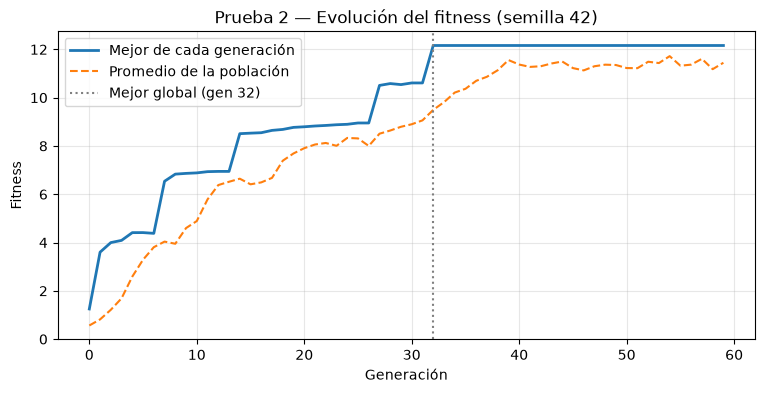

,Generación,Mejor,Promedio
0,0,1.249,0.564
1,10,6.884,4.890
2,20,8.794,7.908
3,30,10.609,8.899
4,40,12.160,11.371
5,59,12.160,11.445


Mejora total del mejor: 1.249 → 12.160 (+10.911)
Generación en que alcanza el 95 % de la mejora: 32
Generaciones donde el mejor EMPEORA respecto a la anterior: 2
✅ PASA — P2 Evolución


In [11]:
# ===== Prueba 2: evolución =====
h_max = np.array(BASE["hist_max"]); h_avg = np.array(BASE["hist_avg"])
caidas = int(np.sum(np.diff(h_max) < -1e-9))
gen_mejor = int(np.argmax(h_max))
umbral95 = h_max[0] + 0.95 * (h_max.max() - h_max[0])
gen_95 = int(np.argmax(h_max >= umbral95))

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(h_max, label="Mejor de cada generación", lw=2)
ax.plot(h_avg, label="Promedio de la población", lw=1.5, ls="--")
ax.axvline(gen_mejor, color="gray", ls=":", label=f"Mejor global (gen {gen_mejor})")
ax.set_xlabel("Generación"); ax.set_ylabel("Fitness"); ax.set_title("Prueba 2 — Evolución del fitness (semilla 42)")
ax.legend(); ax.grid(alpha=.3); plt.show()

tabla = pd.DataFrame({"Generación": [0, 10, 20, 30, 40, len(h_max) - 1]})
tabla["Mejor"] = [round(h_max[g], 3) for g in tabla["Generación"]]
tabla["Promedio"] = [round(h_avg[g], 3) for g in tabla["Generación"]]
display(tabla)

mejora = h_max.max() - h_max[0]
print(f"Mejora total del mejor: {h_max[0]:.3f} → {h_max.max():.3f} (+{mejora:.3f})")
print(f"Generación en que alcanza el 95 % de la mejora: {gen_95}")
print(f"Generaciones donde el mejor EMPEORA respecto a la anterior: {caidas}")

registrar("P2 Evolución", "Corrida de P1",
          f"Mejor {h_max[0]:.2f} → {h_max.max():.2f}; 95 % de la mejora en gen {gen_95}; {caidas} caídas del mejor",
          mejora > 0,
          "Sin elitismo: el mejor de cada generación puede perderse (caídas). El mejor global sí se conserva."
          if caidas else "El mejor nunca empeoró.")

**Interpretación P2:** El mejor fitness sube de **1.25** (generación 0, casi nada cubierto) a **12.16**, que alcanza en la **generación 32**. En las 27 generaciones restantes ya no mejora: el algoritmo se **estanca** en 5/6 regiones. La subida es por saltos (gens 1, 7, 14, 27 y 32), que coinciden con los momentos en que se cubre una región más. El promedio de la población (11.45 al final) queda muy cerca del mejor, señal de que la población **convergió** y perdió diversidad. Por eso no logra salir a buscar Australia. Que deje de mejorar **no demuestra** que sea el óptimo: otras semillas sí cubren las 6 regiones (P7). Hubo **2 caídas** pequeñas del mejor entre generaciones, porque `ejecutar()` no copia al mejor individuo a la siguiente generación (**no hay elitismo**). La clase sí guarda el mejor global, así que el resultado final no se pierde, pero la búsqueda puede retroceder.

### Prueba 3 — Zonas restringidas por desechos

**Condiciones:** 10 corridas (semillas 1–10) en el escenario oficial.
**Objetivo:** comprobar con el validador independiente que **ningún** satélite de la solución final está dentro de las 3 zonas de desechos, y que la función de fitness castiga de verdad una invasión.

In [12]:
# ===== Prueba 3: zonas de desechos =====
# Estas 10 corridas se reutilizan en las pruebas 4 y 7.
CORRIDAS = [correr_ae(s) for s in SEMILLAS]

filas = []
for c in CORRIDAS:
    inv = [i for i in c["auditoria"]["invasiones"] if i["Tipo"] == "Desechos"]
    filas.append({"Semilla": c["semilla"], "Invasiones a desechos": len(inv),
                  "Detalle": "; ".join(f"Sat {i['Satélite']} en {i['Zona']}" for i in inv) or "—"})
df3 = pd.DataFrame(filas); display(df3)
total_inv = int(df3["Invasiones a desechos"].sum())

# Prueba de efecto real: meter un satélite al centro de cada zona y medir la caída del fitness
sol = copy.deepcopy(BASE["mejor"]); f_ok = evaluar_fitness(sol)
efecto = []
for i, z in enumerate(DEBRIS_ZONES):
    forzada = copy.deepcopy(sol); forzada[0] = list(z["center"])
    efecto.append({"Zona": nombre_zona(z, i, "Zona"), "Fitness original": round(f_ok, 3),
                   "Fitness con satélite 1 dentro": round(evaluar_fitness(forzada), 3),
                   "Detectada por is_valid_position": not is_valid_position(*z["center"])})
display(pd.DataFrame(efecto))
castiga = all(e["Fitness con satélite 1 dentro"] < e["Fitness original"] for e in efecto)

registrar("P3 Zonas de desechos", "10 corridas + satélite forzado dentro de cada zona",
          f"{total_inv} invasiones en 10 soluciones; fitness baja al invadir: {castiga}",
          total_inv == 0 and castiga)

,Semilla,Invasiones a desechos,Detalle
0,1,0,—
1,2,0,—
2,3,0,—
3,4,0,—
4,5,0,—
5,6,0,—
6,7,0,—
7,8,0,—
8,9,0,—
9,10,0,—


,Zona,Fitness original,Fitness con satélite 1 dentro,Detectada por is_valid_position
0,Atlántico Norte,12.16,7.64,True
1,Pacífico Sur,12.16,7.64,True
2,Zona polar norte,12.16,7.64,True


✅ PASA — P3 Zonas de desechos


**Interpretación P3:** **0 invasiones en las 10 soluciones**, verificado con el validador independiente. La restricción se respeta en todas las corridas. La segunda tabla demuestra que la restricción **tiene efecto real**: meter un satélite en cualquiera de las 3 zonas baja el fitness de 12.16 a 7.64. La caída es mayor que la penalización de 2.5 porque ese satélite además deja de cubrir Japón. Así, el algoritmo lo evita. Ojo: es una **penalización** (−2.5 por satélite), no una prohibición. Si cubrir una región de prioridad Alta (+3) exigiera invadir una zona, el algoritmo podría preferir la invasión. Eso se revisa en la Prueba 6.

### Prueba 4 — Posiciones ocupadas (Objetos A y B)

**Condiciones:** las mismas 10 corridas, más un caso extra: un **objeto ocupado nuevo sobre Yucatán** con radio 2° (≈ 222 km). Ahí el satélite solo puede cubrir Yucatán desde un anillo estrecho entre 222 y 300 km del centro.
**Objetivo:** verificar que se respetan las zonas de exclusión de 5° y ver qué pasa cuando una exclusión queda pegada a una región.

In [13]:
# ===== Prueba 4: posiciones ocupadas =====
filas = []
for c in CORRIDAS:
    inv = [i for i in c["auditoria"]["invasiones"] if i["Tipo"] == "Objeto ocupado"]
    dmin = min(distancia_grados(s[0], s[1], *o["center"]) for s in c["mejor"] for o in BLOCKED_OBJECTS)
    filas.append({"Semilla": c["semilla"], "Invasiones a objetos": len(inv),
                  "Distancia mínima a A/B (°)": round(dmin, 2)})
df4 = pd.DataFrame(filas); display(df4)
inv_obj = int(df4["Invasiones a objetos"].sum())

# Caso extra: objeto ocupado sobre Yucatán (radio 2°)
objetos_extra = copy.deepcopy(BLOCKED_OBJECTS) + [{"name": "Objeto C (sobre Yucatán)", "center": (20.5, -89.0), "radius": 2.0}]
with escenario_temporal(objetos=objetos_extra):
    extra = [correr_ae(s) for s in SEMILLAS[:5]]
    res_extra = pd.DataFrame([{"Semilla": c["semilla"],
                               "Invasiones": len(c["auditoria"]["invasiones"]),
                               "Yucatán cubierta": "Yucatán" in c["auditoria"]["cubiertas"],
                               "Dist. a Yucatán (km)": round(min(haversine(s[0], s[1], 20.5, -89.0) for s in c["mejor"]), 1)}
                              for c in extra])
display(res_extra)

registrar("P4 Posiciones ocupadas", "10 corridas + objeto C de 2° sobre Yucatán (5 corridas)",
          f"{inv_obj} invasiones a A/B; con objeto C: {int(res_extra['Invasiones'].sum())} invasiones, "
          f"Yucatán cubierta en {int(res_extra['Yucatán cubierta'].sum())}/5",
          inv_obj == 0 and res_extra["Invasiones"].sum() == 0)

,Semilla,Invasiones a objetos,Distancia mínima a A/B (°)
0,1,0,23.88
1,2,0,24.54
2,3,0,24.64
3,4,0,25.41
4,5,0,23.83
5,6,0,8.80
6,7,0,24.03
7,8,0,5.07
8,9,0,21.98
9,10,0,43.73


,Semilla,Invasiones,Yucatán cubierta,Dist. a Yucatán (km)
0,1,0,True,223.2
1,2,0,True,277.9
2,3,0,True,280.7
3,4,0,True,253.4
4,5,0,True,226.9


✅ PASA — P4 Posiciones ocupadas


**Interpretación P4:** **0 invasiones a A y B** en las 10 corridas. La distancia mínima a esos objetos fue de 5.07° en la semilla 8, apenas 0.07° fuera del radio de 5°: el algoritmo llega a pegarse al límite **sin cruzarlo**. Con el **objeto C** sobre Yucatán, las 5 corridas cubrieron Yucatán sin invadir, colocando el satélite entre 223 y 281 km del centro. Es decir, encontró la franja estrecha que queda entre los 222 km de exclusión y los 300 km de observación. Esto demuestra que la restricción y la cobertura funcionan juntas correctamente.

### Prueba 5 — Espacio reducido

**Condiciones:** radios de las 3 zonas de desechos **×2** y radios de A y B **×2**, más una zona nueva "Índico Sur" (−35°, 75°) de 15°. Se mide el porcentaje de la esfera que queda disponible (Monte Carlo con 20 000 puntos) y se corren 5 semillas.
**Objetivo:** ver cómo cambian la cobertura y la validez cuando hay menos espacio.

In [14]:
# ===== Prueba 5: espacio reducido =====
def fraccion_disponible(n=20000, semilla=0):
    rng = np.random.default_rng(semilla)
    lats = np.degrees(np.arcsin(rng.uniform(-1, 1, n)))   # muestreo uniforme sobre la esfera
    lons = rng.uniform(-180, 180, n)
    return np.mean([is_valid_position(a, b) for a, b in zip(lats, lons)])

libre_base = fraccion_disponible()
desechos_red = [dict(z, radius=z["radius"] * 2) for z in DEBRIS_ZONES] + \
               [{"name": "Índico Sur (nueva)", "center": (-35.0, 75.0), "radius": 15.0}]
objetos_red = [dict(o, radius=o["radius"] * 2) for o in BLOCKED_OBJECTS]

with escenario_temporal(desechos=desechos_red, objetos=objetos_red):
    libre_red = fraccion_disponible()
    reducidas = [correr_ae(s) for s in SEMILLAS[:5]]

comp = pd.DataFrame([
    {"Escenario": "Oficial", "Esfera disponible": f"{libre_base:.1%}",
     "Cobertura media": np.mean([c["auditoria"]["n_cubiertas"] for c in CORRIDAS[:5]]),
     "Fitness medio": np.mean([c["fitness"] for c in CORRIDAS[:5]]),
     "Soluciones válidas": f"{sum(c['auditoria']['valida'] for c in CORRIDAS[:5])}/5"},
    {"Escenario": "Reducido", "Esfera disponible": f"{libre_red:.1%}",
     "Cobertura media": np.mean([c["auditoria"]["n_cubiertas"] for c in reducidas]),
     "Fitness medio": np.mean([c["fitness"] for c in reducidas]),
     "Soluciones válidas": f"{sum(c['auditoria']['valida'] for c in reducidas)}/5"}])
display(comp.round(3))

registrar("P5 Espacio reducido", "Radios ×2 + zona nueva de 15°, 5 corridas",
          f"Disponible {libre_base:.1%} → {libre_red:.1%}; válidas {sum(c['auditoria']['valida'] for c in reducidas)}/5",
          all(c["auditoria"]["valida"] for c in reducidas))

,Escenario,Esfera disponible,Cobertura media,Fitness medio,Soluciones válidas
0,Oficial,97.3%,5.8,12.76,5/5
1,Reducido,87.3%,4.8,11.16,5/5


✅ PASA — P5 Espacio reducido


**Interpretación P5:** El espacio disponible baja de **97.3 % a 87.3 %** de la esfera. Las 5 soluciones siguen siendo válidas, pero la cobertura media cae de **5.8 a 4.8 regiones** y el fitness de 12.76 a 11.16. Ninguna región queda dentro de las zonas ampliadas, así que cubrir las 6 **sigue siendo posible**. La pérdida se debe a que el algoritmo explora peor: más individuos iniciales y más mutaciones caen en zonas prohibidas y se penalizan. Conclusión: reducir el espacio afecta la **capacidad de búsqueda** del algoritmo aunque no cambie qué es alcanzable.

### Prueba 6 — Condición difícil e inviable

**6a (difícil):** se agrega una zona de desechos de 5° (≈ 556 km) centrada en Yucatán. Como el radio de observación es de 300 km, es **imposible** cubrir Yucatán sin invadir la zona. Esperado: el algoritmo deja Yucatán sin cubrir y no invade.

**6b (inviable):** una zona de 180° que cubre toda la Tierra. No existe ninguna posición válida. Esperado: el sistema lo detecta o lo avisa.

In [15]:
# ===== Prueba 6a: condición difícil =====
desechos_dif = copy.deepcopy(DEBRIS_ZONES) + [{"name": "Zona sobre Yucatán", "center": (20.5, -89.0), "radius": 5.0}]
with escenario_temporal(desechos=desechos_dif):
    dificiles = [correr_ae(s) for s in SEMILLAS[:5]]
    df6a = pd.DataFrame([{"Semilla": c["semilla"], "Fitness": round(c["fitness"], 3),
                          "Yucatán cubierta": "Yucatán" in c["auditoria"]["cubiertas"],
                          "Regiones cubiertas": c["auditoria"]["n_cubiertas"],
                          "Invasiones": len(c["auditoria"]["invasiones"])} for c in dificiles])
display(df6a)
paso6a = (df6a["Invasiones"].sum() == 0) and (not df6a["Yucatán cubierta"].any())
registrar("P6a Condición difícil", "Zona de 5° sobre Yucatán (cobertura imposible), 5 corridas",
          f"Yucatán cubierta en {int(df6a['Yucatán cubierta'].sum())}/5; invasiones {int(df6a['Invasiones'].sum())}",
          paso6a, "Renuncia a Yucatán: cubrirla ganaría ~2.39 y la invasión cuesta 2.52 (margen muy pequeño)."
          if paso6a else "El algoritmo invadió para cubrir: la penalización es demasiado baja.")

,Semilla,Fitness,Yucatán cubierta,Regiones cubiertas,Invasiones
0,1,10.770,False,5,0
1,2,10.771,False,5,0
2,3,10.771,False,5,0
3,4,9.763,False,4,0
4,5,8.771,False,4,0


✅ PASA — P6a Condición difícil


In [16]:
# ===== Prueba 6b: condición inviable =====
todo_prohibido = [{"name": "Toda la Tierra", "center": (0.0, 0.0), "radius": 180.0}]
with escenario_temporal(desechos=todo_prohibido):
    t0 = time.time()
    try:
        inv = correr_ae(semilla=7, generaciones=10, poblacion=20)
        error = None
    except Exception as e:
        inv, error = None, repr(e)
    dur = time.time() - t0

if error:
    print("El algoritmo lanzó una excepción:", error)
    registrar("P6b Condición inviable", "Zona de 180°", f"Excepción: {error}", False)
else:
    a = inv["auditoria"]
    print(f"Terminó en {dur:.1f} s sin error. Fitness devuelto: {inv['fitness']:.2f}")
    print(f"Invasiones en la 'mejor' solución: {len(a['invasiones'])} de 8 satélites")
    print("¿El algoritmo avisó que no hay solución válida? → No: devuelve una configuración inválida sin advertencia.")
    registrar("P6b Condición inviable", "Zona de 180° (sin posiciones válidas)",
              f"Sin error; devuelve solución con {len(a['invasiones'])} invasiones y fitness {inv['fitness']:.2f}",
              a["valida"] is False,
              "El validador independiente detecta la invalidez, pero generar_individuo rellena con posiciones "
              "aleatorias sin avisar. Recomendación: devolver un indicador 'factible' en ejecutar().")

Terminó en 0.0 s sin error. Fitness devuelto: -15.92
Invasiones en la 'mejor' solución: 8 de 8 satélites
¿El algoritmo avisó que no hay solución válida? → No: devuelve una configuración inválida sin advertencia.
✅ PASA — P6b Condición inviable


**Interpretación P6:** En **6a**, Yucatán quedó sin cubrir en **5/5 corridas** y no hubo invasiones: el sistema responde bien a un objetivo imposible y sacrifica una región de prioridad Alta para cumplir la restricción. Sin embargo, la razón es aritmética y el margen es **muy pequeño**. Cubrir Yucatán daría +3, pero un satélite fuera de la zona ya recibe ≈ 0.61 por cercanía, así que la ganancia real sería ≈ 2.39. Invadir cuesta 2.5 más 0.02 del bono perdido, es decir 2.52. Con una región de prioridad mayor o una penalización menor, el algoritmo **sí invadiría**. Recomendación: que la penalización sea mucho mayor que cualquier prioridad, o descartar directamente las soluciones inválidas. En **6b**, el algoritmo no falla, pero tampoco avisa: devuelve una configuración con **8 de 8 satélites inválidos** (fitness −15.92) como si fuera la mejor. `generar_individuo()` agota sus 1000 intentos y rellena con posiciones aleatorias inválidas. La prueba **pasa** porque nuestro validador sí detecta la invalidez, pero es una limitación del sistema que se reporta.

### Prueba 7 — Variación entre ejecuciones

**Condiciones:** las 10 corridas de la Prueba 3 (semillas 1–10), con los mismos parámetros. Además, se repite la semilla 42 para comprobar que el resultado es reproducible.
**Objetivo:** medir qué tan diferentes salen los resultados y si son estables.

,Semilla,Fitness,Regiones cubiertas,No cubiertas,Válida,Tiempo (s)
0,1,13.16,6,—,True,0.286
1,2,13.16,6,—,True,0.284
2,3,13.16,6,—,True,0.323
3,4,13.16,6,—,True,0.335
4,5,11.16,5,Japón,True,0.408
5,6,11.16,5,Japón,True,0.387
6,7,7.16,4,"Amazonía, Yucatán",True,0.297
7,8,12.16,5,Australia,True,0.760
8,9,13.16,6,—,True,1.201
9,10,12.16,5,Australia,True,1.138


,Fitness,Regiones cubiertas,Tiempo (s)
mean,11.960,5.400,0.542
std,1.874,0.699,0.359
min,7.160,4.000,0.284
max,13.160,6.000,1.201


,Corridas cubierta (de 10)
Yucatán,9
Amazonía,9
California,10
Sahel,10
Japón,8
Australia,8


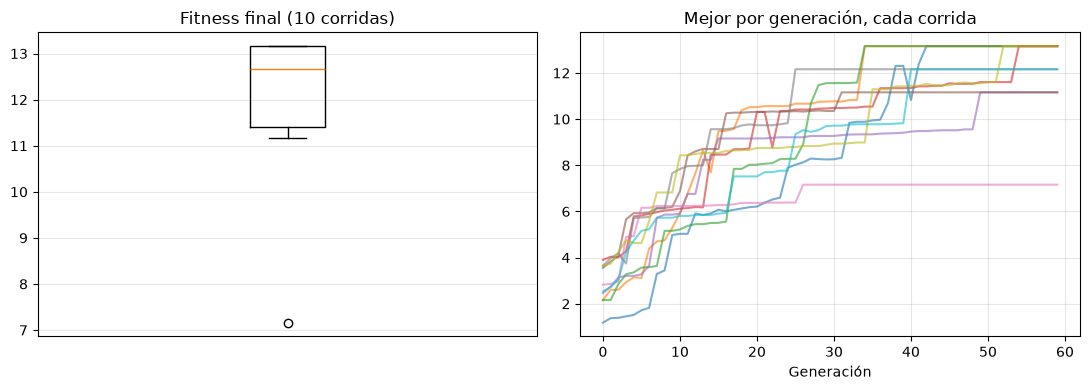

Coeficiente de variación del fitness: 15.7%   |   Semilla 42 reproducible: True
✅ PASA — P7 Variación


In [17]:
# ===== Prueba 7: variación entre ejecuciones =====
df7 = pd.DataFrame([{"Semilla": c["semilla"], "Fitness": c["fitness"],
                     "Regiones cubiertas": c["auditoria"]["n_cubiertas"],
                     "No cubiertas": ", ".join(sorted(set(REGIONS) - set(c["auditoria"]["cubiertas"]))) or "—",
                     "Válida": c["auditoria"]["valida"], "Tiempo (s)": c["tiempo_s"]} for c in CORRIDAS])
display(df7.round(3))

resumen7 = df7[["Fitness", "Regiones cubiertas", "Tiempo (s)"]].agg(["mean", "std", "min", "max"]).round(3)
display(resumen7)
cv = df7["Fitness"].std() / df7["Fitness"].mean()

# Frecuencia con la que cada región queda cubierta
freq = pd.Series({r: sum(r in c["auditoria"]["cubiertas"] for c in CORRIDAS) for r in REGIONS}, name="Corridas cubierta (de 10)")
display(freq.to_frame())

# Reproducibilidad: misma semilla → mismo resultado
repetida = correr_ae(semilla=42)
reproducible = np.allclose(np.array(repetida["mejor"]), np.array(BASE["mejor"]))

fig, axs = plt.subplots(1, 2, figsize=(11, 4))
axs[0].boxplot(df7["Fitness"]); axs[0].set_title("Fitness final (10 corridas)"); axs[0].set_xticks([])
for c in CORRIDAS: axs[1].plot(c["hist_max"], alpha=.6)
axs[1].set_title("Mejor por generación, cada corrida"); axs[1].set_xlabel("Generación")
for a in axs: a.grid(alpha=.3)
plt.tight_layout(); plt.show()

print(f"Coeficiente de variación del fitness: {cv:.1%}   |   Semilla 42 reproducible: {reproducible}")
registrar("P7 Variación", "10 semillas, mismos parámetros + repetición de semilla 42",
          f"Fitness {df7['Fitness'].mean():.2f} ± {df7['Fitness'].std():.2f} (CV {cv:.1%}); "
          f"cobertura {df7['Regiones cubiertas'].mean():.1f} ± {df7['Regiones cubiertas'].std():.1f}; reproducible: {reproducible}",
          reproducible and df7["Válida"].all())

**Interpretación P7:** Fitness **11.96 ± 1.87** (coeficiente de variación de 15.7 %, mediana ≈ 12.7). Se cubren **6/6 regiones en 5 de 10 corridas**, 5/6 en 4 corridas y 4/6 en una (semilla 7). Todas las soluciones son válidas y la semilla 42 da exactamente el mismo resultado al repetirse, así que el sistema es **reproducible**. Las regiones que más se pierden son Japón y Australia (8/10 corridas cubiertas cada una). Son las más aisladas, en el otro lado del planeta respecto al grupo América–África. La semilla 7 es un **caso atípico** (punto aislado en el boxplot): se estancó desde la generación 25 en 7.16 y perdió dos regiones de prioridad Alta. Esto muestra que el algoritmo **puede quedar atrapado en óptimos locales** según la población inicial. En las curvas también se ven **caídas** del mejor en algunas corridas (por ejemplo, cerca de las generaciones 22 y 40), lo que confirma la falta de elitismo observada en la Prueba 2. Conclusión: una sola corrida no basta para defender la solución; hay que reportar varias.

### Prueba 8 — Cambio en las condiciones (punto 3.3)

**Condiciones:** se toma la solución de la Prueba 1 y se cambia el escenario **sin volver a optimizar**:
- **8a:** cambio de prioridades: Australia pasa a Alta (3) y Yucatán a Normal (1).
- **8b:** aparece una zona de desechos nueva de 4° justo donde está el satélite 1 de la solución.

Después se reoptimiza para comparar.
**Objetivo:** saber si la configuración anterior sigue siendo válida y qué tanto empeora.

In [18]:
# ===== Prueba 8: cambio de condiciones =====
sol_prev = copy.deepcopy(BASE["mejor"])
filas = []

# 8a: cambio de prioridades
regiones_8a = copy.deepcopy(REGIONS)
regiones_8a["Australia"]["priority"] = 3
regiones_8a["Yucatán"]["priority"] = 1
with escenario_temporal(regiones=regiones_8a):
    f_prev = evaluar_fitness(sol_prev); valida_prev = auditar(sol_prev)["valida"]
    nueva = correr_ae(42)
filas.append({"Cambio": "8a Prioridades", "Fitness solución anterior": f_prev,
              "¿Sigue válida?": valida_prev, "Fitness reoptimizado": nueva["fitness"],
              "Australia cubierta (antes → después)": f"{'Australia' in auditar(sol_prev)['cubiertas']} → {'Australia' in nueva['auditoria']['cubiertas']}"})

# 8b: nueva zona sobre el satélite 1 de la solución anterior
desechos_8b = copy.deepcopy(DEBRIS_ZONES) + [{"name": "Zona nueva sobre Sat 1", "center": tuple(sol_prev[0]), "radius": 4.0}]
with escenario_temporal(desechos=desechos_8b):
    f_prev_b = evaluar_fitness(sol_prev); aud_prev_b = auditar(sol_prev)
    nueva_b = correr_ae(42)
filas.append({"Cambio": "8b Zona nueva", "Fitness solución anterior": f_prev_b,
              "¿Sigue válida?": aud_prev_b["valida"], "Fitness reoptimizado": nueva_b["fitness"],
              "Australia cubierta (antes → después)": "—"})

df8 = pd.DataFrame(filas); display(df8.round(3))
print(f"Fitness original de la solución en el escenario oficial: {BASE['fitness']:.3f}")
print(f"8b: invasiones de la solución anterior = {len(aud_prev_b['invasiones'])}; "
      f"invasiones tras reoptimizar = {len(nueva_b['auditoria']['invasiones'])}")

paso8 = valida_prev and (not aud_prev_b["valida"]) and nueva_b["auditoria"]["valida"]
registrar("P8 Cambio de condiciones", "8a prioridades; 8b zona nueva sobre Sat 1",
          f"8a: anterior sigue válida ({valida_prev}); 8b: anterior inválida ({not aud_prev_b['valida']}), "
          f"reoptimizada válida ({nueva_b['auditoria']['valida']})", paso8)

,Cambio,Fitness solución anterior,¿Sigue válida?,Fitness reoptimizado,Australia cubierta (antes → después)
0,8a Prioridades,10.16,True,11.160,False → True
1,8b Zona nueva,9.64,False,10.601,—


Fitness original de la solución en el escenario oficial: 12.160
8b: invasiones de la solución anterior = 1; invasiones tras reoptimizar = 0
✅ PASA — P8 Cambio de condiciones


**Interpretación P8:** **8a:** con las nuevas prioridades, la solución anterior **sigue siendo válida**, pero su fitness baja de 12.16 a 10.16 porque no cubría Australia, que ahora vale 3. Al reoptimizar sube a 11.16 y Australia pasa a estar cubierta: el algoritmo **reacciona a las prioridades**. **8b:** la zona nueva deja la solución anterior **inválida** (1 invasión, fitness 9.64). Al reoptimizar se obtiene una solución válida con fitness 10.60. En resumen, un cambio de prioridades solo cambia la puntuación, mientras que una **zona nueva** sí invalida la solución y obliga a reoptimizar. El sistema permite detectarlo porque se puede re-evaluar cualquier configuración guardada contra el escenario nuevo.

### Prueba 9 (propia del equipo) — ¿El algoritmo evolutivo realmente ayuda?

**Pregunta:** ¿el AE es mejor que generar configuraciones válidas al azar y quedarse con la mejor?
**Condiciones:** **mismo presupuesto** de evaluaciones (60 × 50 = 3000), mismas 10 semillas. La búsqueda aleatoria usa el mismo `generar_individuo()` del Integrante 2.
**Por qué importa:** si el azar empata al AE, la selección, el cruce y la mutación no están aportando nada. Es la evidencia más directa de que el algoritmo resuelve el problema.

,Semilla,AE fitness,Aleatorio fitness,AE regiones,Aleatorio regiones,AE gana
0,1,13.16,4.160,6,2,True
1,2,13.16,5.560,6,2,True
2,3,13.16,3.763,6,1,True
3,4,13.16,3.900,6,1,True
4,5,11.16,3.670,5,1,True
5,6,11.16,3.667,5,1,True
6,7,7.16,4.149,4,1,True
7,8,12.16,3.718,5,1,True
8,9,13.16,4.170,6,1,True
9,10,12.16,4.038,5,1,True


,AE fitness,Aleatorio fitness,AE regiones,Aleatorio regiones
mean,11.960,4.080,5.400,1.200
std,1.874,0.559,0.699,0.422


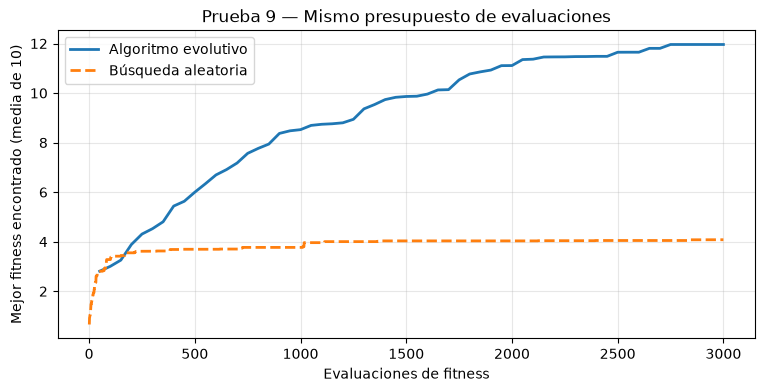

✅ PASA — P9 Propia: AE vs aleatorio


In [19]:
# ===== Prueba 9 (propia): AE vs búsqueda aleatoria =====
def busqueda_aleatoria(semilla, evaluaciones=GEN_PRUEBA * POB_PRUEBA):
    random.seed(semilla); np.random.seed(semilla)
    gen = AlgoritmoEvolutivoConstelacion(evaluar_fitness, is_valid_position, 8)
    mejor, f_mejor, curva = None, float("-inf"), []
    for _ in range(evaluaciones):
        ind = gen.generar_individuo(); f = evaluar_fitness(ind)
        if f > f_mejor: mejor, f_mejor = ind, f
        curva.append(f_mejor)
    return mejor, f_mejor, curva

aleatorias = [busqueda_aleatoria(s) for s in SEMILLAS]
df9 = pd.DataFrame({"Semilla": SEMILLAS,
                    "AE fitness": [c["fitness"] for c in CORRIDAS],
                    "Aleatorio fitness": [a[1] for a in aleatorias],
                    "AE regiones": [c["auditoria"]["n_cubiertas"] for c in CORRIDAS],
                    "Aleatorio regiones": [auditar(a[0])["n_cubiertas"] for a in aleatorias]})
df9["AE gana"] = df9["AE fitness"] > df9["Aleatorio fitness"]
display(df9.round(3))
display(df9[["AE fitness", "Aleatorio fitness", "AE regiones", "Aleatorio regiones"]].agg(["mean", "std"]).round(3))

# Curvas comparables: el AE evalúa POB_PRUEBA individuos por generación
fig, ax = plt.subplots(figsize=(9, 4))
ae_acum = np.mean([np.maximum.accumulate(c["hist_max"]) for c in CORRIDAS], axis=0)
al = np.mean([a[2] for a in aleatorias], axis=0)
ax.plot(np.arange(1, GEN_PRUEBA + 1) * POB_PRUEBA, ae_acum, label="Algoritmo evolutivo", lw=2)
ax.plot(np.arange(1, len(al) + 1), al, label="Búsqueda aleatoria", lw=2, ls="--")
ax.set_xlabel("Evaluaciones de fitness"); ax.set_ylabel("Mejor fitness encontrado (media de 10)")
ax.set_title("Prueba 9 — Mismo presupuesto de evaluaciones"); ax.legend(); ax.grid(alpha=.3); plt.show()

victorias = int(df9["AE gana"].sum())
registrar("P9 Propia: AE vs aleatorio", "3000 evaluaciones, 10 semillas",
          f"AE gana en {victorias}/10; fitness medio AE {df9['AE fitness'].mean():.2f} vs aleatorio {df9['Aleatorio fitness'].mean():.2f}",
          victorias >= 8)

**Interpretación P9:** Con el mismo presupuesto de 3000 evaluaciones, el AE gana en **10/10 semillas**: fitness medio **11.96 contra 4.08** y **5.4 regiones cubiertas contra 1.2**. Incluso la **peor** corrida del AE (7.16, semilla 7) supera a la **mejor** búsqueda aleatoria (5.56). En la gráfica, durante las primeras ~200 evaluaciones ambos métodos van igual, porque la generación inicial del AE también es aleatoria. A partir de ahí el AE sigue subiendo, mientras la búsqueda aleatoria se estanca en ≈ 4: casi nunca acierta varias regiones a la vez, porque un círculo de 300 km es un blanco muy pequeño en el planeta. Esto es evidencia de que la selección, el cruce y la mutación **sí mejoran** las configuraciones, y que no es solo cuestión de generar muchas al azar.

### Resumen de pruebas

In [20]:
# ===== Resumen de la Sección 4 =====
import os
RESUMEN_PRUEBAS = pd.DataFrame(REGISTRO_PRUEBAS)
display(RESUMEN_PRUEBAS)
print(f"\nPruebas que pasan: {(RESUMEN_PRUEBAS['¿Pasa?'] == 'PASA').sum()}/{len(RESUMEN_PRUEBAS)}")
os.makedirs("resultados", exist_ok=True)
RESUMEN_PRUEBAS.to_csv("resultados/resumen_pruebas.csv", index=False, encoding="utf-8-sig")
df7.to_csv("resultados/variacion_10_corridas.csv", index=False, encoding="utf-8-sig")
print("Guardado en resultados/resumen_pruebas.csv y resultados/variacion_10_corridas.csv")

,Prueba,Condiciones,Resultado,¿Pasa?,Observación
0,P0 Funciones base,"Distancias conocidas, centros y borde de zonas",10/10 casos correctos,PASA,is_valid_position usa 111 km/° (el valor exact...
1,P1 Escenario inicial,"Datos oficiales, semilla 42","5/6 regiones cubiertas, fitness 12.16, 0 invas...",PASA,Paso = 8 satélites y ninguna invasión (la cobe...
2,P2 Evolución,Corrida de P1,Mejor 1.25 → 12.16; 95 % de la mejora en gen 3...,PASA,Sin elitismo: el mejor de cada generación pued...
3,P3 Zonas de desechos,10 corridas + satélite forzado dentro de cada ...,0 invasiones en 10 soluciones; fitness baja al...,PASA,
4,P4 Posiciones ocupadas,10 corridas + objeto C de 2° sobre Yucatán (5 ...,0 invasiones a A/B; con objeto C: 0 invasiones...,PASA,
5,P5 Espacio reducido,"Radios ×2 + zona nueva de 15°, 5 corridas",Disponible 97.3% → 87.3%; válidas 5/5,PASA,
6,P6a Condición difícil,Zona de 5° sobre Yucatán (cobertura imposible)...,Yucatán cubierta en 0/5; invasiones 0,PASA,Renuncia a Yucatán: cubrirla ganaría ~2.39 y l...
7,P6b Condición inviable,Zona de 180° (sin posiciones válidas),Sin error; devuelve solución con 8 invasiones ...,PASA,El validador independiente detecta la invalide...
8,P7 Variación,"10 semillas, mismos parámetros + repetición de...",Fitness 11.96 ± 1.87 (CV 15.7%); cobertura 5.4...,PASA,
9,P8 Cambio de condiciones,8a prioridades; 8b zona nueva sobre Sat 1,8a: anterior sigue válida (True); 8b: anterior...,PASA,



Pruebas que pasan: 11/11
Guardado en resultados/resumen_pruebas.csv y resultados/variacion_10_corridas.csv


## Sección 5: Análisis de Resultados y Conclusiones (Integrante 5)
> **Definición del problema y análisis técnico:**
> * Las restricciones espaciales se aplicaron mediante penalizaciones matemáticas en la función de fitness.
> * El algoritmo logra explorar configuraciones válidas evitando los puntos prohibidos de desechos espaciales.